# Student Stress Level Detection

## 1. Setup

In [1]:
!pip -q install imbalanced-learn xgboost shap

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
import tensorflow as tf
tf.random.set_seed(RANDOM_STATE)

In [3]:
# GPU (T4) configuration
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        # Avoid TensorFlow grabbing all GPU memory up front, so XGBoost can also use the GPU.
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"TensorFlow sees {len(gpus)} GPU(s):", [g.name for g in gpus])
    except RuntimeError as e:
        print("Could not set memory growth (must be set before GPUs are initialized):", e)
else:
    print("No GPU detected by TensorFlow — MLP/RNN will train on CPU. ")

!nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv


TensorFlow sees 1 GPU(s): ['/physical_device:GPU:0']
name, memory.total [MiB], memory.used [MiB]
Tesla T4, 15360 MiB, 3 MiB


## 2. Load Data

In [4]:
from google.colab import files

# upload directly
uploaded = files.upload()   # select raw_google_form_export.csv
DATA_PATH = list(uploaded.keys())[0] if uploaded else "raw_google_form_export.csv"

df_raw = pd.read_csv(DATA_PATH, encoding="latin1")
print("Shape:", df_raw.shape)
df_raw.head()

Saving raw_google_form_export.csv to raw_google_form_export.csv
Shape: (3000, 19)


,Timestamp,1. Age\nExample: 23 [Restricted to 19ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,2. Gender\nExample: Male,3. Study_Hours (per day) \nExample: 3,4. Class_Attendance (%) \nExample: 85,5. Tuition (Private Coaching) \nExample: Yes,6. Exam_Frequency (per semester) \nExample: 4,7. Assignment_Load (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,8. Sleep_Hours (per day) \nExample: 6,9. Physical_Exercise (hours per week) \nExample: 2,10. Social_Media_Use (hours per day) \nExample: 3,11. Screen_Time (hours per day) \nExample: 6,12. Family_Income_Level \nExample: Middle,13. Peer_Pressure (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,14. Family_Support (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,15. Anxiety_Level (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,16. University_Type \nExample: Public University,17. Stress_Score (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï,18. Stress_Level \nExample: Moderate
0,2025/10/01 12:00:00 AM GMT+6,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,2025/10/01 12:36:28 AM GMT+6,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High
2,2025/10/01 01:12:57 AM GMT+6,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,16,Medium
3,2025/10/01 01:49:26 AM GMT+6,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,16,Medium
4,2025/10/01 02:25:55 AM GMT+6,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,1,Low


In [5]:
raw_cols = df_raw.columns.tolist()
clean_names = {
    raw_cols[0]:  "Timestamp",
    raw_cols[1]:  "Age",
    raw_cols[2]:  "Gender",
    raw_cols[3]:  "Study_Hours",
    raw_cols[4]:  "Class_Attendance",
    raw_cols[5]:  "Tuition",
    raw_cols[6]:  "Exam_Frequency",
    raw_cols[7]:  "Assignment_Load",
    raw_cols[8]:  "Sleep_Hours",
    raw_cols[9]:  "Physical_Exercise",
    raw_cols[10]: "Social_Media_Use",
    raw_cols[11]: "Screen_Time",
    raw_cols[12]: "Family_Income_Level",
    raw_cols[13]: "Peer_Pressure",
    raw_cols[14]: "Family_Support",
    raw_cols[15]: "Anxiety_Level",
    raw_cols[16]: "University_Type",
    raw_cols[17]: "Stress_Score",
    raw_cols[18]: "Stress_Level",  }
df = df_raw.rename(columns=clean_names)
df = df.drop(columns=["Timestamp"])
print(df.shape)
df.head()

(3000, 18)


,Age,Gender,Study_Hours,Class_Attendance,Tuition,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,Social_Media_Use,Screen_Time,Family_Income_Level,Peer_Pressure,Family_Support,Anxiety_Level,University_Type,Stress_Score,Stress_Level
0,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High
2,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,16,Medium
3,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,16,Medium
4,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,1,Low


## 3. Exploratory Data Analysis

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

n_dupes = df.duplicated().sum()
print(f"\nFully duplicated rows: {n_dupes}")

Missing values per column:
Age                    0
Gender                 0
Study_Hours            0
Class_Attendance       0
Tuition                0
Exam_Frequency         0
Assignment_Load        0
Sleep_Hours            0
Physical_Exercise      0
Social_Media_Use       0
Screen_Time            0
Family_Income_Level    0
Peer_Pressure          0
Family_Support         0
Anxiety_Level          0
University_Type        0
Stress_Score           0
Stress_Level           0
dtype: int64

Fully duplicated rows: 0


In [7]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
categorical_cols.remove("Stress_Level")  # keep target separate

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

df[numeric_cols].describe().T

Numeric columns: ['Age', 'Study_Hours', 'Class_Attendance', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'Stress_Score']
Categorical columns: ['Gender', 'Tuition', 'Physical_Exercise', 'Family_Income_Level', 'University_Type']


,count,mean,std,min,25%,50%,75%,max
Age,3000.0,21.517333,1.705678,19.0,20.0,21.0,23.0,24.0
Study_Hours,3000.0,4.488667,2.858659,0.0,2.0,4.0,7.0,9.0
Class_Attendance,3000.0,68.872333,17.442576,40.0,54.0,69.0,84.0,99.0
Exam_Frequency,3000.0,5.025667,2.592023,1.0,3.0,5.0,7.0,9.0
Assignment_Load,3000.0,4.996000,2.594654,1.0,3.0,5.0,7.0,9.0
Sleep_Hours,3000.0,6.519000,1.687381,4.0,5.0,7.0,8.0,9.0
Social_Media_Use,3000.0,3.487000,2.288721,0.0,2.0,3.0,5.0,7.0
Screen_Time,3000.0,5.918333,3.185129,1.0,3.0,6.0,9.0,11.0
Peer_Pressure,3000.0,4.984000,2.567478,1.0,3.0,5.0,7.0,9.0
Family_Support,3000.0,5.027000,2.568100,1.0,3.0,5.0,7.0,9.0


In [8]:
for c in categorical_cols:
    print(f"\n{c}:")
    print(df[c].value_counts())


Gender:
Gender
Female    1538
Male      1462
Name: count, dtype: int64

Tuition:
Tuition
No     1545
Yes    1455
Name: count, dtype: int64

Physical_Exercise:
Physical_Exercise
No     1551
Yes    1449
Name: count, dtype: int64

Family_Income_Level:
Family_Income_Level
Medium    1333
Low       1059
High       608
Name: count, dtype: int64

University_Type:
University_Type
Public University      1003
National University    1000
Private University      997
Name: count, dtype: int64


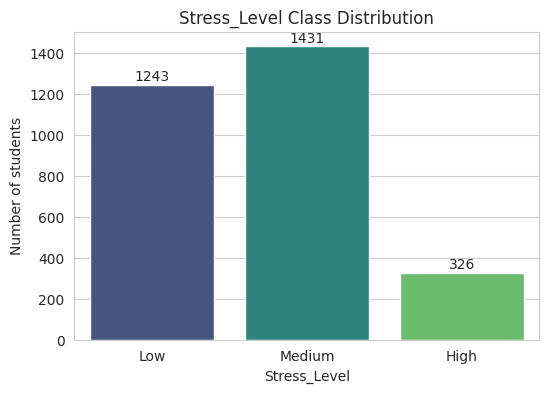

Stress_Level
Low       1243
Medium    1431
High       326
Name: count, dtype: int64

Class proportions:
Stress_Level
Low       0.414
Medium    0.477
High      0.109
Name: count, dtype: float64


In [9]:
order = ["Low", "Medium", "High"]
counts = df["Stress_Level"].value_counts().reindex(order)

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=counts.index, y=counts.values, palette="viridis")
plt.title("Stress_Level Class Distribution")
plt.ylabel("Number of students")
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, str(v), ha="center")
plt.show()

print(counts)
print("\nClass proportions:")
print((counts / counts.sum()).round(3))

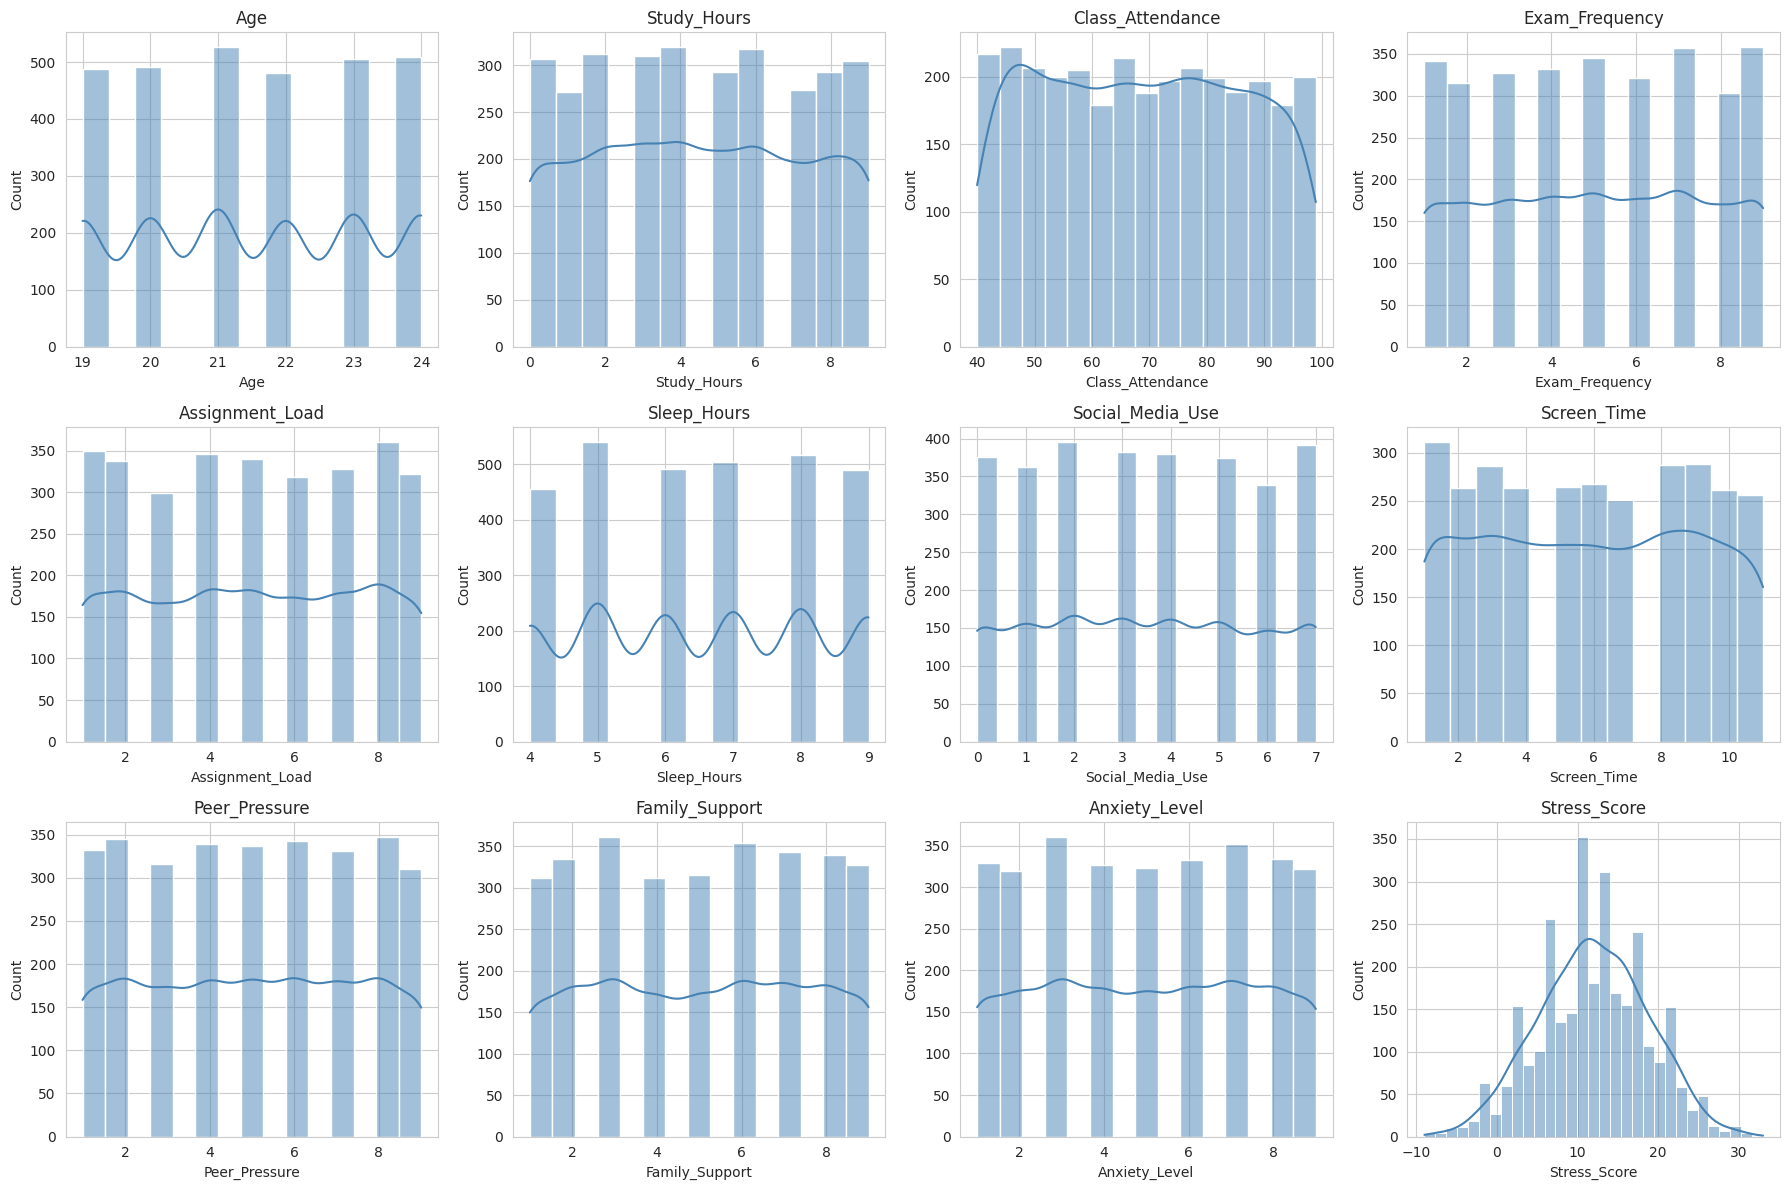

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

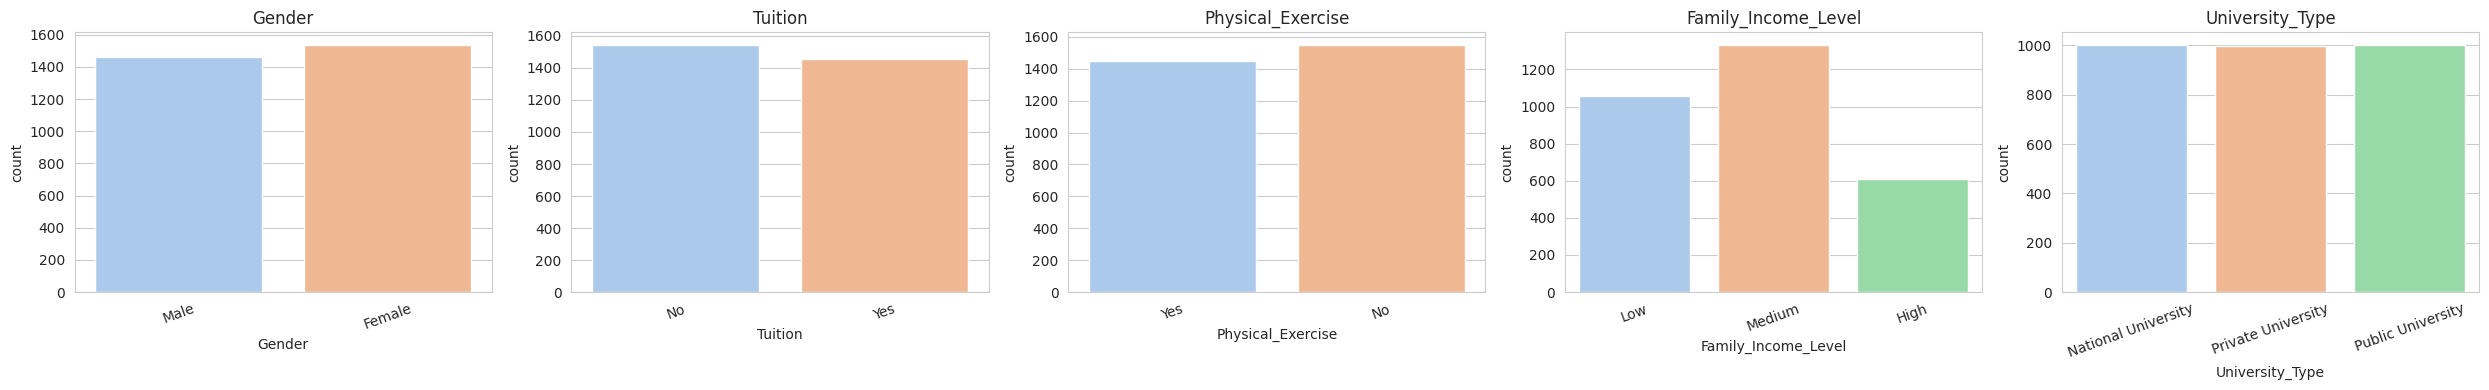

In [11]:
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(5 * len(categorical_cols), 4))
if len(categorical_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, categorical_cols):
    sns.countplot(x=df[col], ax=ax, palette="pastel")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

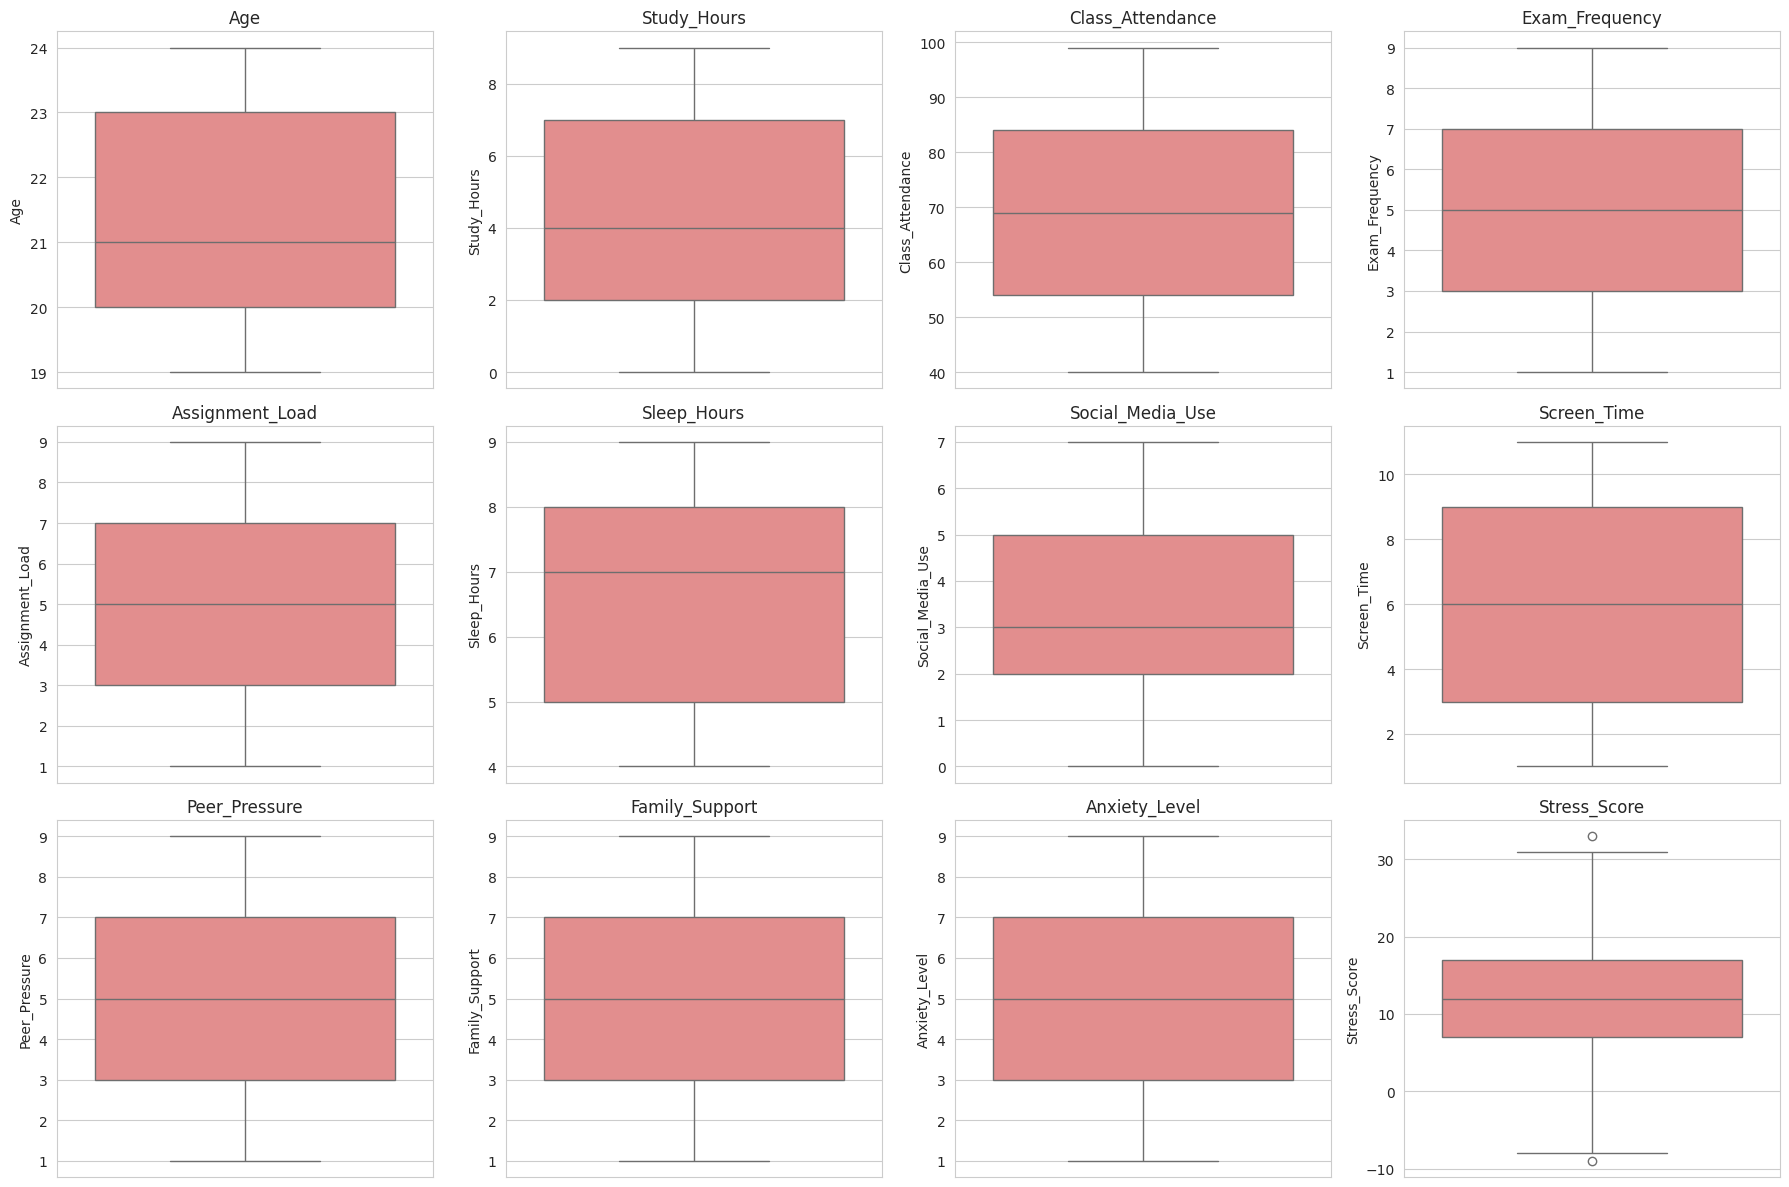

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="lightcoral")
    axes[i].set_title(col)
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

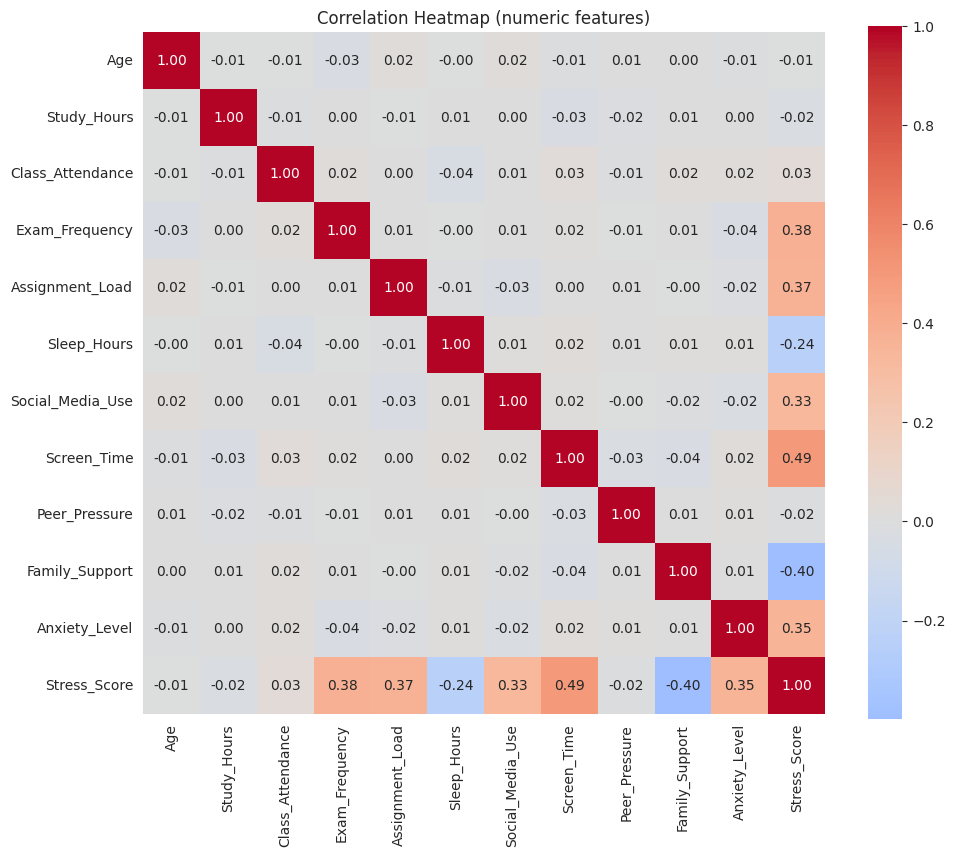

In [13]:
plt.figure(figsize=(11, 9))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (numeric features)")
plt.show()

In [14]:
leak_check = df.groupby("Stress_Level")["Stress_Score"].agg(["min", "max", "mean", "count"])
leak_check = leak_check.reindex(order)
print(leak_check)

              min  max       mean  count
Stress_Level                            
Low            -9   10   5.458568   1243
Medium         11   20  14.918239   1431
High           21   33  23.361963    326


## 4. Data Cleaning

In [15]:
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
after = df.shape[0]
print(f"Removed {before - after} duplicate rows. New shape: {df.shape}")

Removed 0 duplicate rows. New shape: (3000, 18)


In [16]:
for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [17]:
df_model = df.drop(columns=["Stress_Score"]).copy()  # excluded: direct leakage of the target
print(df_model.shape)
df_model.head()

(3000, 17)


,Age,Gender,Study_Hours,Class_Attendance,Tuition,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,Social_Media_Use,Screen_Time,Family_Income_Level,Peer_Pressure,Family_Support,Anxiety_Level,University_Type,Stress_Level
0,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,Medium
1,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,High
2,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,Medium
3,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,Medium
4,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,Low


In [18]:
numeric_cols_model = [c for c in numeric_cols if c != "Stress_Score"]

corr_model = df_model[numeric_cols_model].corr().abs()
upper = corr_model.where(np.triu(np.ones(corr_model.shape), k=1).astype(bool))

CORR_THRESHOLD = 0.90
to_drop = [col for col in upper.columns if (upper[col] > CORR_THRESHOLD).any()]
print("Highly correlated columns flagged for removal (threshold = 0.90):", to_drop)

if to_drop:
    df_model = df_model.drop(columns=to_drop)
    numeric_cols_model = [c for c in numeric_cols_model if c not in to_drop]

print("Shape after redundancy check:", df_model.shape)

Highly correlated columns flagged for removal (threshold = 0.90): []
Shape after redundancy check: (3000, 17)


In [19]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

outlier_summary = {}
for col in numeric_cols_model:
    lower, upper_b = iqr_bounds(df_model[col])
    n_out = ((df_model[col] < lower) | (df_model[col] > upper_b)).sum()
    outlier_summary[col] = {"lower": lower, "upper": upper_b, "n_outliers": n_out}

outlier_df = pd.DataFrame(outlier_summary).T
outlier_df

,lower,upper,n_outliers
Age,15.5,27.5,0.0
Study_Hours,-5.5,14.5,0.0
Class_Attendance,9.0,129.0,0.0
Exam_Frequency,-3.0,13.0,0.0
Assignment_Load,-3.0,13.0,0.0
Sleep_Hours,0.5,12.5,0.0
Social_Media_Use,-2.5,9.5,0.0
Screen_Time,-6.0,18.0,0.0
Peer_Pressure,-3.0,13.0,0.0
Family_Support,-3.0,13.0,0.0


In [20]:
mask = pd.Series(True, index=df_model.index)
for col in numeric_cols_model:
    lower, upper_b, _ = outlier_summary[col].values()
    mask &= df_model[col].between(lower, upper_b)

before = df_model.shape[0]
df_model = df_model[mask].reset_index(drop=True)
after = df_model.shape[0]
print(f"Removed {before - after} outlier rows ({(before-after)/before:.2%}). New shape: {df_model.shape}")

Removed 0 outlier rows (0.00%). New shape: (3000, 17)


In [21]:
print(df_model["Stress_Level"].value_counts().reindex(order))

Stress_Level
Low       1243
Medium    1431
High       326
Name: count, dtype: int64


In [22]:
print("Original shape:", df_model.shape)

print("Duplicate rows:", df_model.duplicated().sum())

Original shape: (3000, 17)
Duplicate rows: 0


## 5. Feature Encoding

In [23]:
from sklearn.preprocessing import LabelEncoder

# Encode target
target_encoder = LabelEncoder()
df_model["Stress_Level"] = target_encoder.fit_transform(df_model["Stress_Level"])

# Save class names in the correct order
CLASS_NAMES = list(target_encoder.classes_)
N_CLASSES = len(CLASS_NAMES)

# One-hot encode categorical input features
X = pd.get_dummies(
    df_model.drop(columns=["Stress_Level"]),
    drop_first=True
)

# Target
y = df_model["Stress_Level"]

print("Feature matrix:", X.shape, " Classes:", CLASS_NAMES)

Feature matrix: (3000, 18)  Classes: ['High', 'Low', 'Medium']


In [24]:
X

,Age,Study_Hours,Class_Attendance,Exam_Frequency,Assignment_Load,Sleep_Hours,Social_Media_Use,Screen_Time,Peer_Pressure,Family_Support,Anxiety_Level,Gender_Male,Tuition_Yes,Physical_Exercise_Yes,Family_Income_Level_Low,Family_Income_Level_Medium,University_Type_Private University,University_Type_Public University
0,24,9,71,7,4,6,6,9,6,3,5,True,False,True,True,False,False,False
1,24,8,43,6,8,5,6,8,3,7,8,False,True,True,False,True,False,False
2,21,4,56,3,6,5,7,9,2,5,3,False,True,True,True,False,True,False
3,23,4,46,8,6,8,5,6,8,6,5,False,False,False,False,True,True,False
4,20,8,46,5,1,6,0,7,5,6,2,True,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,20,6,48,7,9,5,0,9,5,2,3,False,True,False,False,True,False,False
2996,20,2,72,1,2,8,2,4,2,3,6,True,True,True,False,True,True,False
2997,20,3,87,5,7,9,1,10,5,6,4,False,False,True,False,True,True,False
2998,21,8,57,3,2,7,2,1,7,4,6,True,False,True,True,False,True,False


## 6. Train / Validation / Test Split

In [25]:
from sklearn.model_selection import train_test_split

# Split into 80% Train and 20% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Split Temp into 10% Validation and 10% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)

for name, split_y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"\n{name} class proportions:")
    print(split_y.value_counts(normalize=True).sort_index().round(3))

Train: (2400, 18)  Val: (300, 18)  Test: (300, 18)

Train class proportions:
Stress_Level
0    0.109
1    0.414
2    0.477
Name: proportion, dtype: float64

Val class proportions:
Stress_Level
0    0.107
1    0.417
2    0.477
Name: proportion, dtype: float64

Test class proportions:
Stress_Level
0    0.110
1    0.413
2    0.477
Name: proportion, dtype: float64


## 7. Feature Scaling

In [26]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on the training split ONLY, then apply it to val/test —
# this must happen after the split so no information from val/test leaks
# into the scaling parameters (mean/std).
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val), columns=X_val.columns, index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print("Scaled shapes -> Train:", X_train_scaled.shape, " Val:", X_val_scaled.shape, " Test:", X_test_scaled.shape)

Scaled shapes -> Train: (2400, 18)  Val: (300, 18)  Test: (300, 18)


## 8. Class Balancing (SMOTE)

In [27]:
from imblearn.over_sampling import SMOTE

# SMOTE is fit and applied to the training split ONLY. The validation and
# test sets must stay untouched (real, unaltered class distribution) so
# evaluation reflects real-world performance rather than synthetic data.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().sort_index().to_dict())
print("After SMOTE: ", y_train_bal.value_counts().sort_index().to_dict())

Before SMOTE: {0: 261, 1: 994, 2: 1145}
After SMOTE:  {0: 1145, 1: 1145, 2: 1145}


## 9. Evaluation Utilities

In [28]:
from sklearn.metrics import ( accuracy_score, precision_score, recall_score, f1_score,
roc_auc_score, confusion_matrix, classification_report
)
results_table = []
def evaluate_model(name, y_true, y_pred, y_proba=None, cv_score=None, plot=True):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    roc_auc = np.nan
    if y_proba is not None:
        try:
            roc_auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro")
        except Exception as e:
            print(f"ROC-AUC could not be computed for {name}: {e}")

    results_table.append({
        "Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec,
        "F1_macro": f1, "ROC_AUC": roc_auc,
        "CV_F1_macro": cv_score if cv_score is not None else np.nan
    })

    print(f"\n===== {name} — Test Set Performance =====")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

    if plot:
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(4.5, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        plt.title(f"Confusion Matrix — {name}")
        plt.ylabel("True label")
        plt.xlabel("Predicted label")
        plt.tight_layout()
        plt.show()

    return acc, prec, rec, f1, roc_auc

## 10. Standalone Models — Hyperparameter Tuning

### 10.1 Logistic Regression

Best LR params: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV F1 (macro): 0.9784

===== Logistic Regression — Test Set Performance =====
              precision    recall  f1-score   support

        High       0.85      1.00      0.92        33
         Low       1.00      1.00      1.00       124
      Medium       1.00      0.96      0.98       143

    accuracy                           0.98       300
   macro avg       0.95      0.99      0.97       300
weighted avg       0.98      0.98      0.98       300



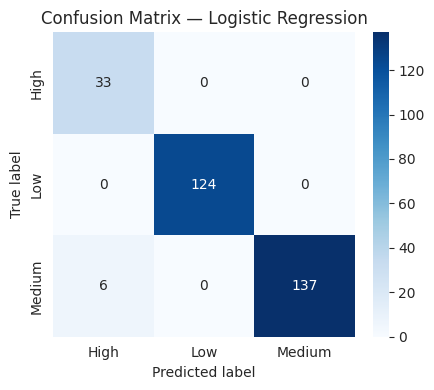

(0.98,
 0.9487179487179488,
 0.9860139860139859,
 0.9650793650793651,
 np.float64(0.9996139741362672))

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_param_grid = {
    "C": [0.01, 0.1],
    "penalty": ["l2"],
    "solver": ["lbfgs"]
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=RANDOM_STATE),
    lr_param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
lr_grid.fit(X_train_bal, y_train_bal)

print("Best LR params:", lr_grid.best_params_)
print("Best CV F1 (macro):", round(lr_grid.best_score_, 4))

best_lr = lr_grid.best_estimator_

y_pred = best_lr.predict(X_test_scaled)
y_proba = best_lr.predict_proba(X_test_scaled)
evaluate_model("Logistic Regression", y_test, y_pred, y_proba, cv_score=lr_grid.best_score_)

### 10.2 Decision Tree

Best DT params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2}
Best CV F1 (macro): 0.7923

===== Decision Tree — Test Set Performance =====
              precision    recall  f1-score   support

        High       0.54      0.61      0.57        33
         Low       0.78      0.76      0.77       124
      Medium       0.70      0.69      0.69       143

    accuracy                           0.71       300
   macro avg       0.67      0.69      0.68       300
weighted avg       0.71      0.71      0.71       300



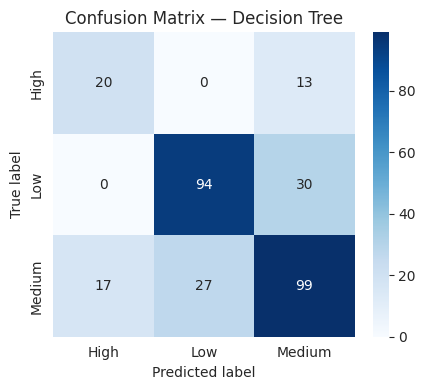

(0.71,
 0.6715277144214404,
 0.6854776048324437,
 0.6778374507697816,
 np.float64(0.7609113268807915))

In [30]:
from sklearn.tree import DecisionTreeClassifier

dt_param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"],
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    dt_param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
dt_grid.fit(X_train_bal, y_train_bal)

print("Best DT params:", dt_grid.best_params_)
print("Best CV F1 (macro):", round(dt_grid.best_score_, 4))

best_dt = dt_grid.best_estimator_

y_pred = best_dt.predict(X_test_scaled)
y_proba = best_dt.predict_proba(X_test_scaled)
evaluate_model("Decision Tree", y_test, y_pred, y_proba, cv_score=dt_grid.best_score_)

### 10.3 Support Vector Machine (SVM)

Best SVM params: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV F1 (macro): 0.9585

===== SVM — Test Set Performance =====
              precision    recall  f1-score   support

        High       0.90      0.79      0.84        33
         Low       0.94      0.96      0.95       124
      Medium       0.92      0.92      0.92       143

    accuracy                           0.92       300
   macro avg       0.92      0.89      0.90       300
weighted avg       0.92      0.92      0.92       300



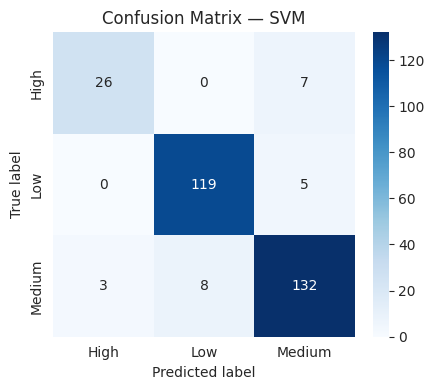

(0.9233333333333333,
 0.9167420882734486,
 0.8902110434368499,
 0.9022591586372655,
 np.float64(0.9838206637002284))

In [31]:
from sklearn.svm import SVC

svm_param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf"],
    "gamma": ["auto"],
}

svm_grid = GridSearchCV(
    SVC(probability=True, random_state=RANDOM_STATE),
    svm_param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
svm_grid.fit(X_train_bal, y_train_bal)

print("Best SVM params:", svm_grid.best_params_)
print("Best CV F1 (macro):", round(svm_grid.best_score_, 4))

best_svm = svm_grid.best_estimator_

y_pred = best_svm.predict(X_test_scaled)
y_proba = best_svm.predict_proba(X_test_scaled)
evaluate_model("SVM", y_test, y_pred, y_proba, cv_score=svm_grid.best_score_)

### 10.4 Random Forest

Best RF params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 (macro): 0.9127

===== Random Forest — Test Set Performance =====
              precision    recall  f1-score   support

        High       0.95      0.58      0.72        33
         Low       0.90      0.90      0.90       124
      Medium       0.83      0.91      0.87       143

    accuracy                           0.87       300
   macro avg       0.90      0.80      0.83       300
weighted avg       0.88      0.87      0.87       300



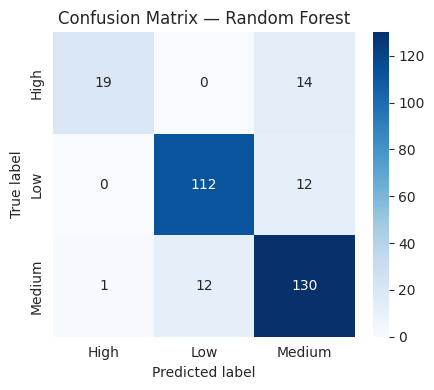

(0.87,
 0.8955197132616487,
 0.7960247637666993,
 0.8299240519727963,
 np.float64(0.9695754260777453))

In [32]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5],
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    rf_param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
rf_grid.fit(X_train_bal, y_train_bal)

print("Best RF params:", rf_grid.best_params_)
print("Best CV F1 (macro):", round(rf_grid.best_score_, 4))

best_rf = rf_grid.best_estimator_

y_pred = best_rf.predict(X_test_scaled)
y_proba = best_rf.predict_proba(X_test_scaled)
evaluate_model("Random Forest", y_test, y_pred, y_proba, cv_score=rf_grid.best_score_)

### 10.5 XGBoost

Best XGBoost params: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Best CV F1 (macro): 0.9272

===== XGBoost — Test Set Performance =====
              precision    recall  f1-score   support

        High       0.93      0.79      0.85        33
         Low       0.97      0.94      0.95       124
      Medium       0.90      0.97      0.93       143

    accuracy                           0.93       300
   macro avg       0.94      0.90      0.91       300
weighted avg       0.93      0.93      0.93       300



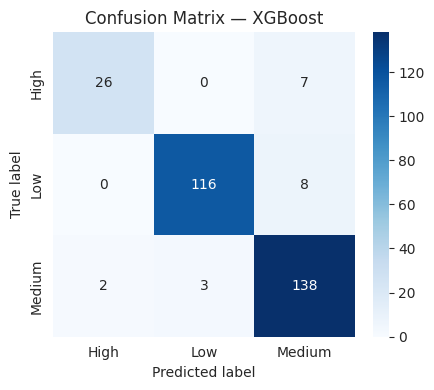

(0.9333333333333333,
 0.9351073762838468,
 0.8961325412938316,
 0.9132079863713137,
 np.float64(0.991589377937228))

In [33]:
from xgboost import XGBClassifier
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
}

xgb_grid = GridSearchCV(
    XGBClassifier(
        objective="multi:softprob", num_class=N_CLASSES,
        eval_metric="mlogloss", random_state=RANDOM_STATE
    ),
    xgb_param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
xgb_grid.fit(X_train_bal, y_train_bal)

print("Best XGBoost params:", xgb_grid.best_params_)
print("Best CV F1 (macro):", round(xgb_grid.best_score_, 4))

best_xgb = xgb_grid.best_estimator_

y_pred = best_xgb.predict(X_test_scaled)
y_proba = best_xgb.predict_proba(X_test_scaled)
evaluate_model("XGBoost", y_test, y_pred, y_proba, cv_score=xgb_grid.best_score_)

## 11. Multi-Layer Perceptron (MLP)

In [34]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score as f1_score_fn

N_FEATURES = X_train_bal.shape[1]

def build_mlp(hidden_layers, activation, learning_rate):
    model = keras.Sequential()
    model.add(layers.Input(shape=(N_FEATURES,)))
    for units in hidden_layers:
        model.add(layers.Dense(units, activation=activation))
        model.add(layers.Dropout(0.2))
    model.add(layers.Dense(N_CLASSES, activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

# Manual search space: (hidden_layers, activation, learning_rate, batch_size)
mlp_configs = [
    ([64, 32],       "relu", 0.001, 32),
    ([128, 64],      "relu", 0.001, 32),
    ([128, 64, 32],  "relu", 0.0005, 64),
    ([64, 32],       "tanh", 0.001, 32),
]

mlp_search_results = []
best_mlp_val_f1 = -1
best_mlp_model = None
best_mlp_config = None
best_mlp_history = None

for hidden_layers, activation, lr, batch_size in mlp_configs:
    model = build_mlp(hidden_layers, activation, lr)
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )
    history = model.fit(
        X_train_bal, y_train_bal,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0,
    )
    val_pred = np.argmax(model.predict(X_val_scaled, verbose=0), axis=1)
    val_f1 = f1_score_fn(y_val, val_pred, average="macro")
    n_epochs_run = len(history.history["loss"])

    mlp_search_results.append({
        "hidden_layers": hidden_layers, "activation": activation,
        "learning_rate": lr, "batch_size": batch_size,
        "epochs_run": n_epochs_run, "val_f1_macro": val_f1,
    })
    print(f"layers={hidden_layers}, act={activation}, lr={lr}, batch={batch_size} "
          f"-> val F1(macro)={val_f1:.4f} (stopped after {n_epochs_run} epochs)")

    if val_f1 > best_mlp_val_f1:
        best_mlp_val_f1 = val_f1
        best_mlp_model = model
        best_mlp_config = (hidden_layers, activation, lr, batch_size)
        best_mlp_history = history

print("\nBest MLP config:", best_mlp_config, "-> val F1(macro) =", round(best_mlp_val_f1, 4))
pd.DataFrame(mlp_search_results).sort_values("val_f1_macro", ascending=False)

layers=[64, 32], act=relu, lr=0.001, batch=32 -> val F1(macro)=0.9811 (stopped after 65 epochs)
layers=[128, 64], act=relu, lr=0.001, batch=32 -> val F1(macro)=0.9786 (stopped after 50 epochs)
layers=[128, 64, 32], act=relu, lr=0.0005, batch=64 -> val F1(macro)=0.9585 (stopped after 55 epochs)
layers=[64, 32], act=tanh, lr=0.001, batch=32 -> val F1(macro)=1.0000 (stopped after 81 epochs)

Best MLP config: ([64, 32], 'tanh', 0.001, 32) -> val F1(macro) = 1.0


,hidden_layers,activation,learning_rate,batch_size,epochs_run,val_f1_macro
3,"[64, 32]",tanh,0.0010,32,81,1.000000
0,"[64, 32]",relu,0.0010,32,65,0.981107
1,"[128, 64]",relu,0.0010,32,50,0.978593
2,"[128, 64, 32]",relu,0.0005,64,55,0.958530


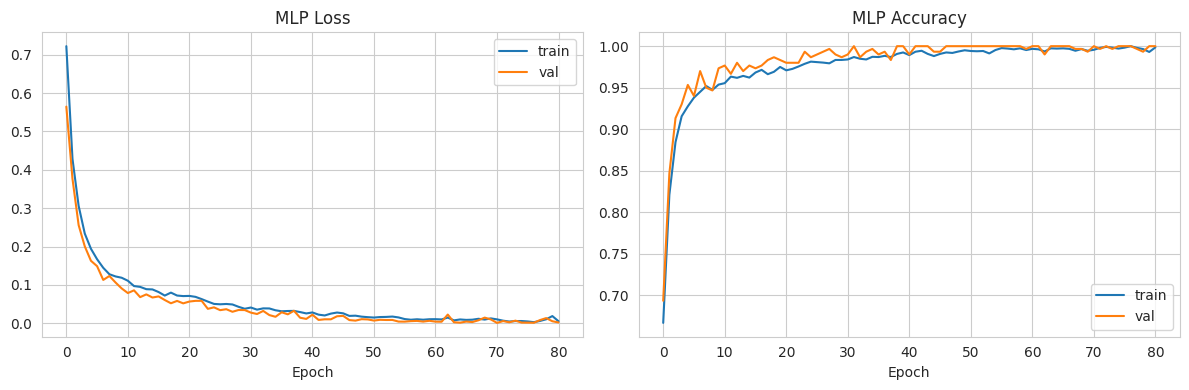

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_mlp_history.history["loss"], label="train")
axes[0].plot(best_mlp_history.history["val_loss"], label="val")
axes[0].set_title("MLP Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(best_mlp_history.history["accuracy"], label="train")
axes[1].plot(best_mlp_history.history["val_accuracy"], label="val")
axes[1].set_title("MLP Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

MLP 5-fold CV F1 (macro): 0.9991

===== MLP — Test Set Performance =====
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        33
         Low       1.00      1.00      1.00       124
      Medium       1.00      1.00      1.00       143

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



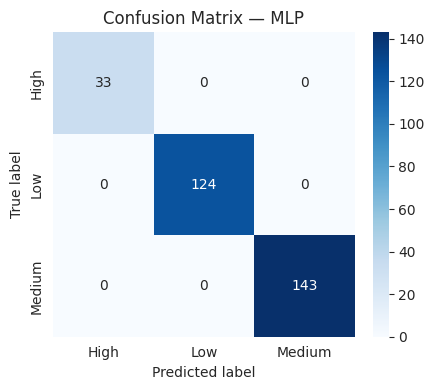

(1.0, 1.0, 1.0, 1.0, np.float64(1.0))

In [36]:
mlp_test_proba = best_mlp_model.predict(X_test_scaled, verbose=0)
mlp_test_pred = np.argmax(mlp_test_proba, axis=1)

# 5-fold CV score for MLP (re-trains the chosen architecture per fold, so the comparison
from sklearn.model_selection import StratifiedKFold

hidden_layers, activation, lr, batch_size = best_mlp_config
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1_scores = []
X_train_arr, y_train_arr = X_train_bal.values, y_train_bal

for fold_idx, (tr_idx, te_idx) in enumerate(skf.split(X_train_arr, y_train_arr)):
    fold_model = build_mlp(hidden_layers, activation, lr)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    fold_model.fit(
        X_train_arr[tr_idx], y_train_arr[tr_idx],
        validation_data=(X_train_arr[te_idx], y_train_arr[te_idx]),
        epochs=60, batch_size=batch_size, callbacks=[es], verbose=0,
    )
    fold_pred = np.argmax(fold_model.predict(X_train_arr[te_idx], verbose=0), axis=1)
    cv_f1_scores.append(f1_score_fn(y_train_arr[te_idx], fold_pred, average="macro"))

mlp_cv_score = np.mean(cv_f1_scores)
print("MLP 5-fold CV F1 (macro):", round(mlp_cv_score, 4))
evaluate_model("MLP", y_test, mlp_test_pred, mlp_test_proba, cv_score=mlp_cv_score)

## 12. Recurrent Neural Network (RNN)

In [37]:
# The engineered features are tabular (one row per student, no natural time
# ordering), so to apply a recurrent architecture we treat each sample as a
# sequence of length 1 over N_FEATURES "channels" — i.e. reshape
# (n_samples, n_features) -> (n_samples, 1, n_features). This is a standard,
# defensible way to benchmark RNN-family models against tabular baselines
# when the data itself has no genuine temporal structure; it is noted as a
# methodological choice in the write-up rather than presented as a natural fit.

X_train_rnn = X_train_bal.values.reshape((X_train_bal.shape[0], 1, N_FEATURES))
X_val_rnn = X_val_scaled.values.reshape((X_val_scaled.shape[0], 1, N_FEATURES))
X_test_rnn = X_test_scaled.values.reshape((X_test_scaled.shape[0], 1, N_FEATURES))

print("RNN input shapes -> Train:", X_train_rnn.shape, " Val:", X_val_rnn.shape, " Test:", X_test_rnn.shape)

def build_rnn(rnn_units, cell_type, learning_rate, dropout=0.2):
    """cell_type: 'simple_rnn' or 'lstm'"""
    model = keras.Sequential()
    model.add(layers.Input(shape=(1, N_FEATURES)))
    for i, units in enumerate(rnn_units):
        return_sequences = i < len(rnn_units) - 1
        if cell_type == "lstm":
            model.add(layers.LSTM(units, return_sequences=return_sequences))
        else:
            model.add(layers.SimpleRNN(units, return_sequences=return_sequences))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(N_CLASSES, activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


RNN input shapes -> Train: (3435, 1, 18)  Val: (300, 1, 18)  Test: (300, 1, 18)


In [38]:
# Single, fixed RNN baseline architecture — no hyperparameter search, and a
# reduced training budget (fewer epochs, no restore_best_weights) compared to
# the ensemble's base learners.
# (rnn_units, cell_type, learning_rate, batch_size)
rnn_configs = [
    ([16], "simple_rnn", 0.001, 32),
    ([8],  "simple_rnn", 0.001, 32),
]

rnn_search_results = []
best_rnn_val_f1 = -1
best_rnn_model = None
best_rnn_config = None
best_rnn_history = None

for rnn_units, cell_type, lr, batch_size in rnn_configs:
    model = build_rnn(rnn_units, cell_type, lr)
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )
    history = model.fit(
        X_train_rnn, y_train_bal,
        validation_data=(X_val_rnn, y_val),
        epochs=100,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0,
    )
    val_pred = np.argmax(model.predict(X_val_rnn, verbose=0), axis=1)
    val_f1 = f1_score_fn(y_val, val_pred, average="macro")
    n_epochs_run = len(history.history["loss"])

    rnn_search_results.append({
        "rnn_units": rnn_units, "cell_type": cell_type,
        "learning_rate": lr, "batch_size": batch_size,
        "epochs_run": n_epochs_run, "val_f1_macro": val_f1,
    })
    print(f"units={rnn_units}, cell={cell_type}, lr={lr}, batch={batch_size} "
          f"-> val F1(macro)={val_f1:.4f} (stopped after {n_epochs_run} epochs)")

    if val_f1 > best_rnn_val_f1:
        best_rnn_val_f1 = val_f1
        best_rnn_model = model
        best_rnn_config = (rnn_units, cell_type, lr, batch_size)
        best_rnn_history = history

print("\nBest RNN config:", best_rnn_config, "-> val F1(macro) =", round(best_rnn_val_f1, 4))
pd.DataFrame(rnn_search_results).sort_values("val_f1_macro", ascending=False)


units=[16], cell=simple_rnn, lr=0.001, batch=32 -> val F1(macro)=1.0000 (stopped after 100 epochs)
units=[8], cell=simple_rnn, lr=0.001, batch=32 -> val F1(macro)=1.0000 (stopped after 100 epochs)

Best RNN config: ([16], 'simple_rnn', 0.001, 32) -> val F1(macro) = 1.0


,rnn_units,cell_type,learning_rate,batch_size,epochs_run,val_f1_macro
0,[16],simple_rnn,0.001,32,100,1.0
1,[8],simple_rnn,0.001,32,100,1.0


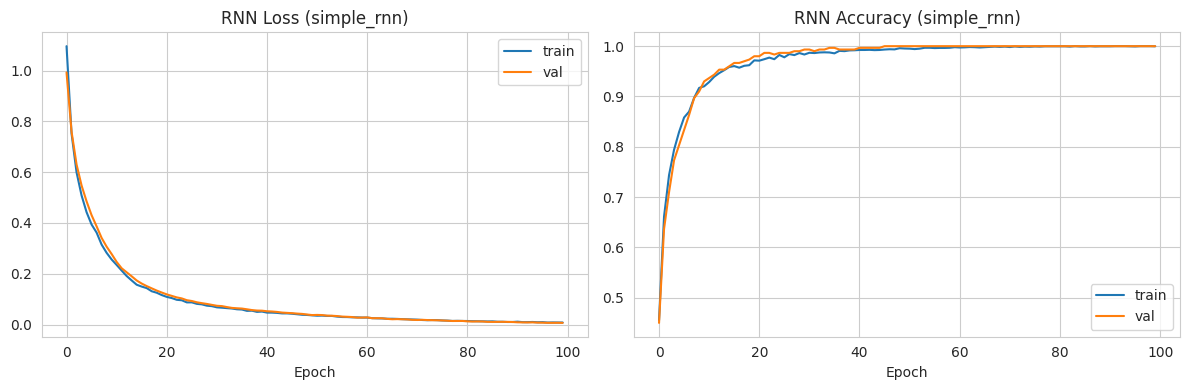

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_rnn_history.history["loss"], label="train")
axes[0].plot(best_rnn_history.history["val_loss"], label="val")
axes[0].set_title(f"RNN Loss ({best_rnn_config[1]})")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(best_rnn_history.history["accuracy"], label="train")
axes[1].plot(best_rnn_history.history["val_accuracy"], label="val")
axes[1].set_title(f"RNN Accuracy ({best_rnn_config[1]})")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


RNN 5-fold CV F1 (macro): 0.9956

===== RNN (simple_rnn) — Test Set Performance =====
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        33
         Low       1.00      1.00      1.00       124
      Medium       1.00      1.00      1.00       143

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



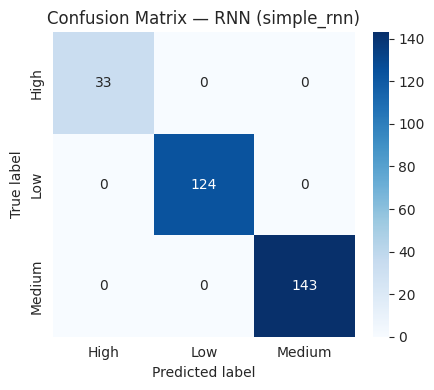

(1.0, 1.0, 1.0, 1.0, np.float64(1.0))

In [40]:
rnn_test_proba = best_rnn_model.predict(X_test_rnn, verbose=0)
rnn_test_pred = np.argmax(rnn_test_proba, axis=1)

# 5-fold CV score for the chosen RNN architecture, same protocol as the MLP CV in Section 11.
rnn_units, cell_type, lr, batch_size = best_rnn_config
skf_rnn = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rnn_cv_f1_scores = []
X_train_rnn_arr, y_train_rnn_arr = X_train_rnn, y_train_bal

for fold_idx, (tr_idx, te_idx) in enumerate(skf_rnn.split(X_train_rnn_arr, y_train_rnn_arr)):
    fold_model = build_rnn(rnn_units, cell_type, lr)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    fold_model.fit(
        X_train_rnn_arr[tr_idx], y_train_rnn_arr[tr_idx],
        validation_data=(X_train_rnn_arr[te_idx], y_train_rnn_arr[te_idx]),
        epochs=60, batch_size=batch_size, callbacks=[es], verbose=0,
    )
    fold_pred = np.argmax(fold_model.predict(X_train_rnn_arr[te_idx], verbose=0), axis=1)
    rnn_cv_f1_scores.append(f1_score_fn(y_train_rnn_arr[te_idx], fold_pred, average="macro"))

rnn_cv_score = np.mean(rnn_cv_f1_scores)
print("RNN 5-fold CV F1 (macro):", round(rnn_cv_score, 4))

rnn_model_label = f"RNN ({cell_type})"
evaluate_model(rnn_model_label, y_test, rnn_test_pred, rnn_test_proba, cv_score=rnn_cv_score)


## 12.5 ProtoNAM (Prototypical Neural Additive Model) — Interpretable Baseline


In [ ]:
# ProtoNAM: Prototypical Neural Additive Model

import math
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("ProtoNAM device:", DEVICE)


class MultiChannelLinear(nn.Module):
    def __init__(self, in_dim, out_dim, n_channel=1):
        super(MultiChannelLinear, self).__init__()
        self.w = torch.nn.Parameter(torch.zeros(n_channel, out_dim, in_dim))
        self.b = torch.nn.Parameter(torch.zeros(1, n_channel, out_dim))
        nn.init.kaiming_uniform_(self.w, a=math.sqrt(3))
        fan_in, _ = torch.nn.init._calculate_fan_in_and_fan_out(self.w)
        bound = 1 / math.sqrt(fan_in)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x):
        return (self.w * x.unsqueeze(-2)).sum(-1) + self.b


class ProtoNAM(nn.Module):
    def __init__(self, problem, n_feat, h_dim, n_proto, n_layers, n_class, dropout=0.0,
                 dropout_output=0.0, output_penalty=0.0, p=1, n_layers_pred=2, batch_norm=False):
        super(ProtoNAM, self).__init__()
        self.problem = problem
        self.n_feat = n_feat
        self.h_dim = h_dim
        self.n_class = n_class
        self.n_layers = n_layers
        self.n_proto = n_proto
        self.p = p
        if self.p == 1:
            self.mask = nn.parameter.Parameter(F.one_hot(torch.arange(n_feat), num_classes=n_feat), requires_grad=False)
        elif self.p == 2:
            mask = torch.stack([torch.arange(self.n_feat).repeat_interleave(self.n_feat), 
            torch.arange(self.n_feat).repeat(self.n_feat)]).transpose(0, 1)
            mask = mask[mask[:, 0] < mask[:, 1]]
            self.mask = nn.parameter.Parameter(F.one_hot(mask[:, 0], num_classes=n_feat) + F.one_hot(mask[:, 1], 
            num_classes=n_feat), requires_grad=False)
        elif self.p == -1:
            self.mask = nn.parameter.Parameter(torch.ones(1, self.n_feat), requires_grad=False)
        self.n_comp = len(self.mask)
        self.output_penalty = output_penalty

        assert self.n_layers > 0

        self.dropout = nn.Dropout(p=dropout)
        self.dropout_output = nn.Dropout(p=dropout_output)
        self.activate = nn.ReLU()

        if batch_norm:
            self.norm = nn.BatchNorm1d(self.n_feat)
        else:
            self.norm = nn.LayerNorm(self.h_dim)
        self.lnorm = nn.LayerNorm(self.h_dim)

        self.enc_list = nn.Sequential(
            nn.Sequential(MultiChannelLinear(1, self.h_dim, self.n_feat), self.norm, self.dropout, self.activate),
            *([nn.Sequential(
                MultiChannelLinear(self.h_dim + 1, self.h_dim, self.n_feat), self.norm, self.dropout, self.activate
            ) for _ in range(self.n_layers - 1)])
        )

        self.center = nn.parameter.Parameter(torch.zeros(self.n_layers, self.n_proto, self.n_feat), requires_grad=True)
        self.coeff = nn.parameter.Parameter(torch.ones(self.n_layers, self.n_proto, self.n_feat), requires_grad=True)
        self.bias = nn.parameter.Parameter(torch.zeros(self.n_layers, self.n_proto, self.n_feat), requires_grad=True)

        if n_layers_pred == 1:
            self.clfs = nn.Sequential(
                *([nn.Sequential(nn.Linear(self.n_feat * self.h_dim, self.n_class)) for _ in range(self.n_layers)])
            )
        else:
            self.clfs = nn.Sequential(
                *([nn.Sequential(
                    nn.Linear(self.n_feat * self.h_dim, self.h_dim),
                    *([it for _ in range(n_layers_pred - 1) for it in (self.lnorm, self.dropout, 
                    self.activate, nn.Linear(self.h_dim, self.n_class))]),
                ) for _ in range(self.n_layers)])
            )

        self.aggs = nn.Sequential(*([nn.Linear(self.n_comp, 1) for _ in range(self.n_layers)]))

        if self.problem == "regression":
            self.criterion = nn.MSELoss()
        elif self.n_class == 1:
            self.criterion = nn.BCEWithLogitsLoss()
        else:
            self.criterion = nn.CrossEntropyLoss()

        nn.init.xavier_normal_(self.center)
        for fc in self.aggs:
            nn.init.xavier_normal_(fc.weight)
        for clf in self.clfs:
            for fc in clf:
                if type(fc) == nn.Linear:
                    nn.init.xavier_normal_(fc.weight)

    def initialize(self, X):
        with torch.no_grad():
            percent_q = 100 * np.arange(start=1.0, stop=self.n_proto + 1) / (self.n_proto + 1)
            self.center[:] = torch.from_numpy(np.percentile(X, percent_q, axis=0)[None])

    def forward(self, x, y, T=1e-8):
        Z = self.encode(x, T=T)
        Logits = []
        output_loss = 0
        for i in range(len(Z)):
            res, loss = self.predict(self.clfs[i], self.aggs[i], Z[i])
            output_loss += loss
            Logits.append(res)
        for i in range(len(Logits) - 1):
            Logits[i + 1] += Logits[i]
        total_loss = 0
        for i in range(len(Logits)):
            total_loss += self.criterion(Logits[i], y)
        return total_loss + self.output_penalty * output_loss, Logits[-1]

    def encode(self, x, T):
        dists = torch.pow(x[:, None, None] - self.center[None], 2)
        x_res = (torch.softmax(-dists / T, dim=-2) * (x[:, None, None] * self.coeff[None] + self.bias[None])).sum(-2)
        Z = []
        for i, layer in enumerate(self.enc_list):
            if i == 0:
                z = layer(x_res[:, i].unsqueeze(-1))
            else:
                z = layer(torch.cat([z, x_res[:, i].unsqueeze(-1)], dim=-1))
            Z.append(z)
        return Z

    def predict(self, clf, agg, z):
        z_comp = z[:, None] * self.mask[None, :, :, None]
        res = clf(z_comp.flatten(start_dim=-2))
        res = self.dropout_output(res)
        loss = res.pow(2).mean()
        res = (res * agg.weight[0, None, :, None]).mean(-2) + agg.bias[None, :]
        return res.squeeze(-1), loss

ProtoNAM device: cuda


In [42]:
def build_protonam(h_dim, n_proto, n_layers, dropout=0.0, n_layers_pred=2, p=1, batch_norm=False):
    torch.manual_seed(RANDOM_STATE)
    model = ProtoNAM(
        problem="classification", n_feat=N_FEATURES, h_dim=h_dim, n_proto=n_proto,
        n_layers=n_layers, n_class=N_CLASSES, dropout=dropout, dropout_output=0.0,
        output_penalty=0.0, p=p, n_layers_pred=n_layers_pred, batch_norm=batch_norm,
    )
    return model


def train_protonam(model, X_train, y_train, X_val, y_val, lr, batch_size,
                    max_epoch=100, tau=16.0, weight_decay=1e-8, patience=10):
    """Trains one ProtoNAM model, using the temperature-annealed prototype
    training schedule from the official repo's Config.train_session (see
    src/config.py), plus early stopping on validation macro-F1 to match the
    MLP/RNN protocol used above (Sections 11-12)."""

    model.initialize(X_train.values if hasattr(X_train, "values") else np.asarray(X_train))
    model.to(DEVICE)

    X_train_t = torch.tensor(np.asarray(X_train), dtype=torch.float32)
    y_train_t = torch.tensor(np.asarray(y_train), dtype=torch.long)
    X_val_t = torch.tensor(np.asarray(X_val), dtype=torch.float32).to(DEVICE)
    y_val_t = torch.tensor(np.asarray(y_val), dtype=torch.long).to(DEVICE)

    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)

    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=max_epoch)

    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_val_f1 = -1
    best_state = None
    best_epoch = 0
    epochs_since_improve = 0

    for epoch in range(max_epoch):
        model.train()
        T = 1 / (1 + math.exp((epoch - max_epoch // 2) / tau))
        running_loss, n_seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss, _ = model(xb, yb, T=T)
            loss = loss.mean()
            loss.backward()
            optim.step()
            running_loss += loss.item() * len(xb)
            n_seen += len(xb)
        scheduler.step()
        train_loss = running_loss / n_seen

        model.eval()
        with torch.no_grad():
            val_loss, val_logits = model(X_val_t, y_val_t, T=1e-8)
            val_loss = val_loss.mean().item()
            val_pred = val_logits.argmax(dim=-1).cpu().numpy()
            val_f1 = f1_score_fn(y_val_t.cpu().numpy(), val_pred, average="macro")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_since_improve = 0
        else:
            epochs_since_improve += 1
            if epochs_since_improve >= patience:
                break

    model.load_state_dict(best_state)
    return model, history, best_val_f1, best_epoch

In [43]:
# Manual search space: (h_dim, n_proto, n_layers, lr, dropout, batch_size)
# Scaled down from the paper's own defaults (h_dim=64, n_proto=8-32, n_layers=4,
# lr=2e-4) since this dataset (~2.4k training rows, one tabular row per student)
# is far smaller than ProtoNAM's original MIMIC / Income / Housing benchmarks.
protonam_configs = [
    (32, 8,  2, 1e-3, 0.1, 32),
    (32, 8,  3, 5e-4, 0.1, 32),
    (64, 16, 3, 5e-4, 0.1, 64),
    (64, 8,  4, 2e-4, 0.0, 64),
]

protonam_search_results = []
best_protonam_val_f1 = -1
best_protonam_model = None
best_protonam_config = None
best_protonam_history = None

for h_dim, n_proto, n_layers, lr, dropout, batch_size in protonam_configs:
    model = build_protonam(h_dim, n_proto, n_layers, dropout=dropout)
    model, history, val_f1, best_epoch = train_protonam(
        model, X_train_bal, y_train_bal, X_val_scaled, y_val,
        lr=lr, batch_size=batch_size, max_epoch=100, tau=16.0, patience=10,
    )
    n_epochs_run = len(history["train_loss"])

    protonam_search_results.append({
        "h_dim": h_dim, "n_proto": n_proto, "n_layers": n_layers,
        "learning_rate": lr, "dropout": dropout, "batch_size": batch_size,
        "epochs_run": n_epochs_run, "best_epoch": best_epoch, "val_f1_macro": val_f1,
    })
    print(f"h_dim={h_dim}, n_proto={n_proto}, n_layers={n_layers}, lr={lr}, "
          f"dropout={dropout}, batch={batch_size} -> val F1(macro)={val_f1:.4f} "
          f"(best epoch {best_epoch}, stopped after {n_epochs_run} epochs)")

    if val_f1 > best_protonam_val_f1:
        best_protonam_val_f1 = val_f1
        best_protonam_model = model
        best_protonam_config = (h_dim, n_proto, n_layers, lr, dropout, batch_size)
        best_protonam_history = history

print("\nBest ProtoNAM config:", best_protonam_config, "-> val F1(macro) =", round(best_protonam_val_f1, 4))
pd.DataFrame(protonam_search_results).sort_values("val_f1_macro", ascending=False)

h_dim=32, n_proto=8, n_layers=2, lr=0.001, dropout=0.1, batch=32 -> val F1(macro)=0.9353 (best epoch 27, stopped after 38 epochs)
h_dim=32, n_proto=8, n_layers=3, lr=0.0005, dropout=0.1, batch=32 -> val F1(macro)=0.9443 (best epoch 34, stopped after 45 epochs)
h_dim=64, n_proto=16, n_layers=3, lr=0.0005, dropout=0.1, batch=64 -> val F1(macro)=0.9359 (best epoch 38, stopped after 49 epochs)
h_dim=64, n_proto=8, n_layers=4, lr=0.0002, dropout=0.0, batch=64 -> val F1(macro)=0.9057 (best epoch 64, stopped after 75 epochs)

Best ProtoNAM config: (32, 8, 3, 0.0005, 0.1, 32) -> val F1(macro) = 0.9443


,h_dim,n_proto,n_layers,learning_rate,dropout,batch_size,epochs_run,best_epoch,val_f1_macro
1,32,8,3,0.0005,0.1,32,45,34,0.944309
2,64,16,3,0.0005,0.1,64,49,38,0.935940
0,32,8,2,0.0010,0.1,32,38,27,0.935319
3,64,8,4,0.0002,0.0,64,75,64,0.905683


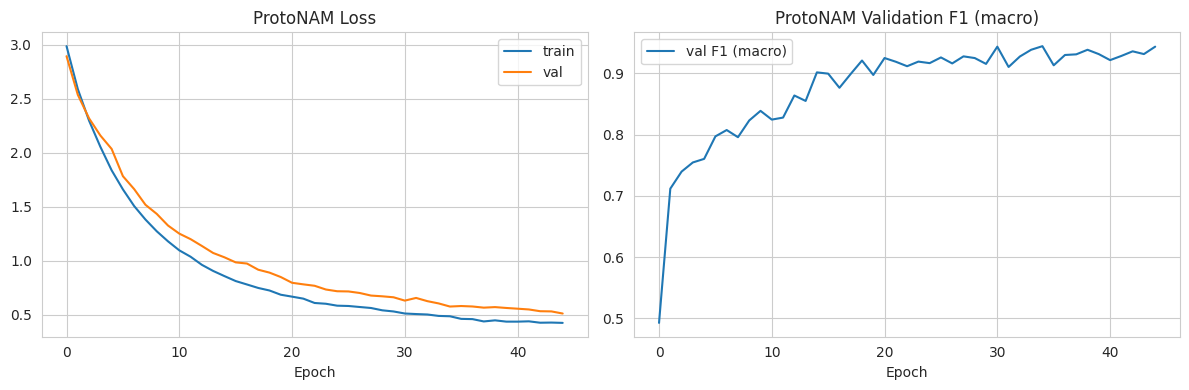

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_protonam_history["train_loss"], label="train")
axes[0].plot(best_protonam_history["val_loss"], label="val")
axes[0].set_title("ProtoNAM Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(best_protonam_history["val_f1"], label="val F1 (macro)")
axes[1].set_title("ProtoNAM Validation F1 (macro)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

ProtoNAM 5-fold CV F1 (macro): 0.9582

===== ProtoNAM — Test Set Performance =====
              precision    recall  f1-score   support

        High       0.97      0.88      0.92        33
         Low       0.96      0.94      0.95       124
      Medium       0.92      0.96      0.94       143

    accuracy                           0.94       300
   macro avg       0.95      0.92      0.94       300
weighted avg       0.94      0.94      0.94       300



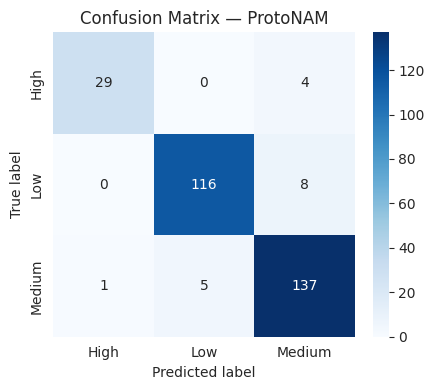

(0.94,
 0.9482691466218007,
 0.9241045692658596,
 0.9353099535095621,
 np.float64(0.9950015468933867))

In [45]:
best_protonam_model.eval()
with torch.no_grad():
    X_test_t = torch.tensor(np.asarray(X_test_scaled), dtype=torch.float32).to(DEVICE)
    y_test_t = torch.tensor(np.asarray(y_test), dtype=torch.long).to(DEVICE)
    _, protonam_test_logits = best_protonam_model(X_test_t, y_test_t, T=1e-8)
    protonam_test_proba = torch.softmax(protonam_test_logits, dim=-1).cpu().numpy()
    protonam_test_pred = protonam_test_proba.argmax(axis=1)

# 5-fold CV score for the chosen ProtoNAM architecture, same protocol as the MLP/RNN CV above.
h_dim, n_proto, n_layers, lr, dropout, batch_size = best_protonam_config
skf_protonam = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
protonam_cv_f1_scores = []
X_train_arr_pn = X_train_bal.values if hasattr(X_train_bal, "values") else np.asarray(X_train_bal)
y_train_arr_pn = np.asarray(y_train_bal)

for fold_idx, (tr_idx, te_idx) in enumerate(skf_protonam.split(X_train_arr_pn, y_train_arr_pn)):
    fold_model = build_protonam(h_dim, n_proto, n_layers, dropout=dropout)
    fold_model, _, _, _ = train_protonam(
        fold_model, X_train_arr_pn[tr_idx], y_train_arr_pn[tr_idx],
        X_train_arr_pn[te_idx], y_train_arr_pn[te_idx],
        lr=lr, batch_size=batch_size, max_epoch=60, tau=16.0, patience=8,
    )
    fold_model.eval()
    with torch.no_grad():
        Xf_t = torch.tensor(X_train_arr_pn[te_idx], dtype=torch.float32).to(DEVICE)
        yf_t = torch.tensor(y_train_arr_pn[te_idx], dtype=torch.long).to(DEVICE)
        _, fold_logits = fold_model(Xf_t, yf_t, T=1e-8)
        fold_pred = fold_logits.argmax(dim=-1).cpu().numpy()
    protonam_cv_f1_scores.append(f1_score_fn(y_train_arr_pn[te_idx], fold_pred, average="macro"))

protonam_cv_score = np.mean(protonam_cv_f1_scores)
print("ProtoNAM 5-fold CV F1 (macro):", round(protonam_cv_score, 4))

evaluate_model("ProtoNAM", y_test, protonam_test_pred, protonam_test_proba, cv_score=protonam_cv_score)

## 13. Standalone Model Comparison

In [46]:
results_df = pd.DataFrame(results_table).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1_macro,ROC_AUC,CV_F1_macro
Model,,,,,,
Logistic Regression,0.9800,0.9487,0.9860,0.9651,0.9996,0.9784
Decision Tree,0.7100,0.6715,0.6855,0.6778,0.7609,0.7923
SVM,0.9233,0.9167,0.8902,0.9023,0.9838,0.9585
Random Forest,0.8700,0.8955,0.7960,0.8299,0.9696,0.9127
XGBoost,0.9333,0.9351,0.8961,0.9132,0.9916,0.9272
MLP,1.0000,1.0000,1.0000,1.0000,1.0000,0.9991
RNN (simple_rnn),1.0000,1.0000,1.0000,1.0000,1.0000,0.9956
ProtoNAM,0.9400,0.9483,0.9241,0.9353,0.9950,0.9582


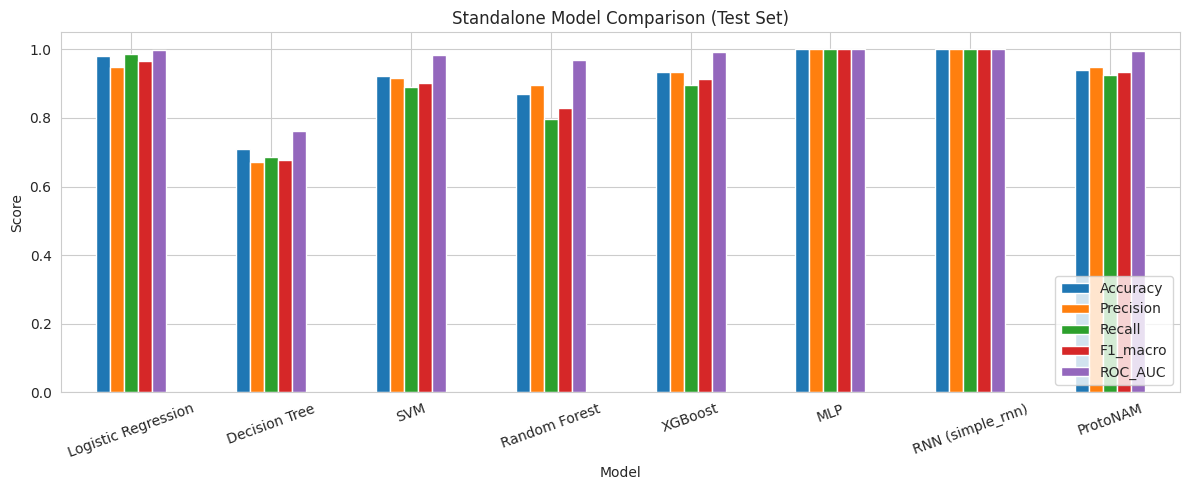

In [47]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1_macro", "ROC_AUC"]
results_df[metrics_to_plot].plot(kind="bar", figsize=(12, 5))
plt.title("Standalone Model Comparison (Test Set)")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 14. Hybrid Stacking Ensemble

In [48]:
# Level-1 base learners: reuse the already-tuned RF and XGBoost, and the already-trained MLP
base_rf = best_rf
base_xgb = best_xgb
base_mlp = best_mlp_model

# Meta-features = concatenated class probabilities from each base learner
def get_meta_features(X):
    rf_proba = base_rf.predict_proba(X)
    xgb_proba = base_xgb.predict_proba(X)
    mlp_proba = base_mlp.predict(X, verbose=0)
    return np.hstack([rf_proba, xgb_proba, mlp_proba])

meta_X_val = get_meta_features(X_val_scaled)     # meta-learner TRAINING features (val set + true y_val)
meta_X_test = get_meta_features(X_test_scaled)   # meta-learner TEST features

print("Meta-feature shape (val):", meta_X_val.shape, " (test):", meta_X_test.shape)


Meta-feature shape (val): (300, 9)  (test): (300, 9)


Meta-learner 5-fold CV F1 (macro) on validation meta-features: 1.0

===== Hybrid Stacking (RF+XGB+MLP -> LR) — Test Set Performance =====
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        33
         Low       1.00      1.00      1.00       124
      Medium       1.00      1.00      1.00       143

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



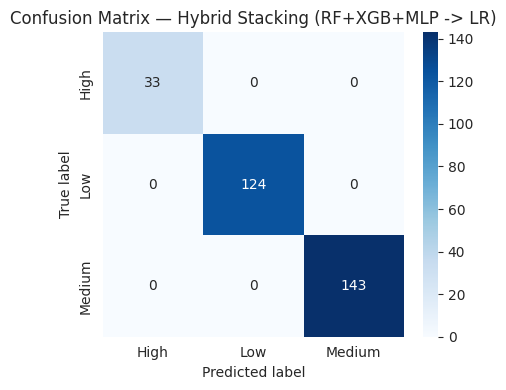

(1.0, 1.0, 1.0, 1.0, np.float64(1.0))

In [49]:
from sklearn.linear_model import LogisticRegression

meta_learner = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
meta_learner.fit(meta_X_val, y_val)

stack_pred = meta_learner.predict(meta_X_test)
stack_proba = meta_learner.predict_proba(meta_X_test)

# Cross-validated F1 of the meta-learner on its own (validation-set) training data
from sklearn.model_selection import cross_val_score
stack_cv_f1 = cross_val_score(
    meta_learner, meta_X_val, y_val, cv=5, scoring="f1_macro"
).mean()
print("Meta-learner 5-fold CV F1 (macro) on validation meta-features:", round(stack_cv_f1, 4))

evaluate_model("Hybrid Stacking (RF+XGB+MLP -> LR)", y_test, stack_pred, stack_proba, cv_score=stack_cv_f1)


## 15. Final Comparison — All Models

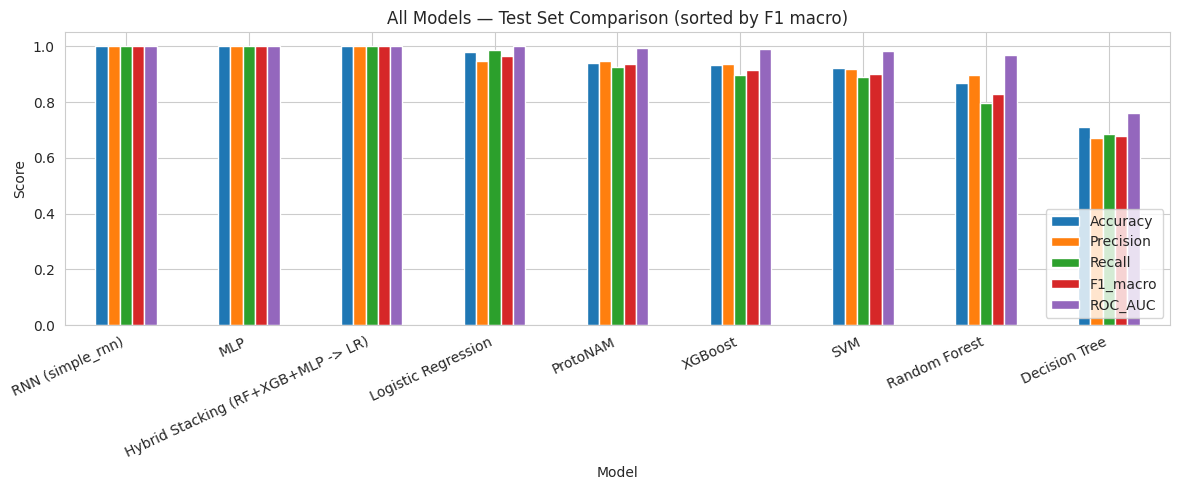

Best model by macro F1: RNN (simple_rnn)


In [50]:
final_results_df = pd.DataFrame(results_table).set_index("Model")
final_results_df = final_results_df.round(4)
final_results_df = final_results_df.sort_values("F1_macro", ascending=False)
final_results_df

fig, ax = plt.subplots(figsize=(12, 5))
final_results_df[["Accuracy", "Precision", "Recall", "F1_macro", "ROC_AUC"]].plot(kind="bar", ax=ax)
plt.title("All Models — Test Set Comparison (sorted by F1 macro)")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Best model by macro F1:", final_results_df.index[0])

## 16. Meta-Learner Contribution

MLP              1.463762
XGBoost          0.549139
Random Forest    0.310206
dtype: float64


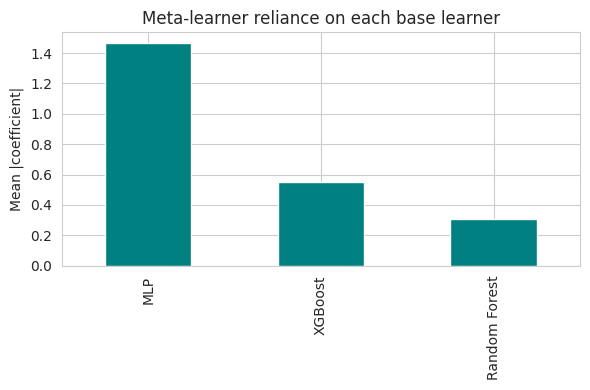

In [51]:
base_learner_blocks = {
    "Random Forest": slice(0, N_CLASSES),
    "XGBoost": slice(N_CLASSES, 2 * N_CLASSES),
    "MLP": slice(2 * N_CLASSES, 3 * N_CLASSES),
}

coef_importance = {}
for name, sl in base_learner_blocks.items():
    coef_importance[name] = np.abs(meta_learner.coef_[:, sl]).mean()

importance_series = pd.Series(coef_importance).sort_values(ascending=False)
print(importance_series)

importance_series.plot(kind="bar", figsize=(6, 4), color="teal", title="Meta-learner reliance on each base learner")
plt.ylabel("Mean |coefficient|")
plt.tight_layout()
plt.show()


## 17. Model Interpretability — SHAP

In [52]:
import shap

explainer = shap.TreeExplainer(base_xgb)
shap_values = explainer.shap_values(X_test_scaled)

# shap_values is a list (per-class) for multi-class XGBoost in older SHAP versions,
# or a 3D array (samples, features, classes) in newer versions — handle both.
if isinstance(shap_values, list):
    shap_values_arr = np.stack(shap_values, axis=-1)
else:
    shap_values_arr = shap_values

print("SHAP values shape:", np.array(shap_values_arr).shape)

SHAP values shape: (300, 18, 3)


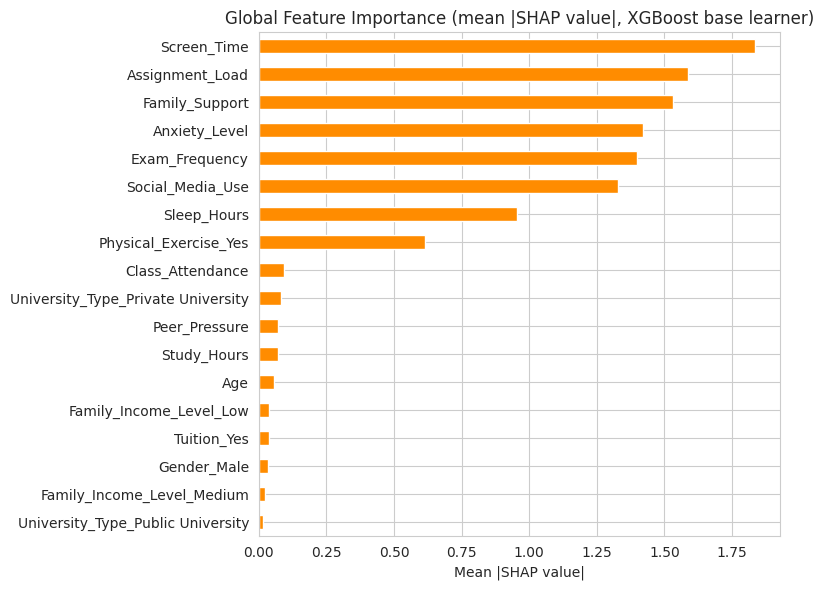

,0
Screen_Time,1.835494
Assignment_Load,1.587284
Family_Support,1.533416
Anxiety_Level,1.420041
Exam_Frequency,1.397288
Social_Media_Use,1.329118
Sleep_Hours,0.955645
Physical_Exercise_Yes,0.613778
Class_Attendance,0.091699
University_Type_Private University,0.081768


In [53]:
mean_abs_shap = np.abs(shap_values_arr).mean(axis=(0, 2)) if shap_values_arr.ndim == 3 else np.abs(shap_values_arr).mean(axis=0)
feat_importance = pd.Series(mean_abs_shap, index=X_test_scaled.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
feat_importance.plot(kind="barh", color="darkorange")
plt.title("Global Feature Importance (mean |SHAP value|, XGBoost base learner)")
plt.xlabel("Mean |SHAP value|")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

feat_importance

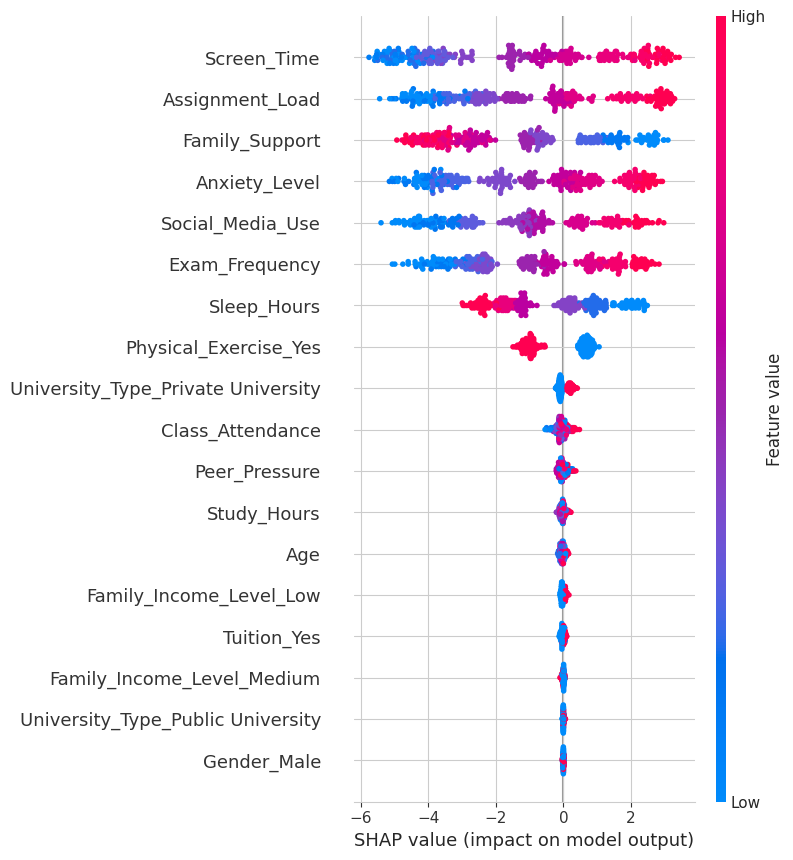

In [54]:
HIGH_CLASS_IDX = CLASS_NAMES.index("High")

if shap_values_arr.ndim == 3:
    shap.summary_plot(shap_values_arr[:, :, HIGH_CLASS_IDX], X_test_scaled, show=True)
else:
    shap.summary_plot(shap_values_arr, X_test_scaled, show=True)